# AI-Powered Sentiment Analysis System
**Month 2 Project – End-to-End NLP & Machine Learning Pipeline**

- **Task:** Multiclass sentiment classification
- **Target classes:** Positive, Negative, Neutral
- **Input:** Customer review text
- **Methods:** Text preprocessing, TF-IDF, supervised ML, cross-validation, hyperparameter tuning and probability calibration
- **Deployment:** Streamlit

> **Dataset note:** The supplied CSV has 10,000 rows but only 300 unique `review_text` values. Exact duplicate review texts are removed before splitting to prevent identical text from appearing in both training and test sets. Therefore, evaluation is based on 300 unique texts, not 10,000 independent reviews. This limitation must be disclosed in the report.

## Setup
Run this cell once in the notebook environment. The project `requirements.txt` is used so the notebook and Streamlit app share dependencies.

In [1]:
%pip install "pandas>=2.0,<3.0" "numpy>=1.24,<3.0" "scikit-learn==1.8.0" "matplotlib>=3.7" "seaborn>=0.12" "joblib>=1.3" "streamlit>=1.30" "ipykernel>=6.0"

  Using cached streamlit-1.66.1-py3-none-any.whl.metadata (10 kB)
  Using cached pytz-2026.6-py2.py3-none-any.whl.metadata (22 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached starlette-1.10.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached uvicorn-0.54.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached python_multipart-0.0.32-py3-none-any.whl.metadata (2.1 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached watchdog-6.0.0-py3-none-win_amd64.whl.metadata (44 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Import libraries

In [1]:
import re
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and understand the dataset
The notebook looks for the CSV in the project's `data/` directory. It works when launched either from the project root or from `notebooks/`.

In [3]:
DATA_FILE = "customer_reviews.csv"
cwd = Path.cwd()

candidate_paths = [
    cwd / "data" / DATA_FILE,
    cwd.parent / "data" / DATA_FILE,
    cwd / DATA_FILE
]

data_path = next((p for p in candidate_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Place it inside the project's data folder."
    )

df_raw = pd.read_csv(data_path)

required_columns = {"review_text", "sentiment", "category", "source"}
missing_columns = required_columns - set(df_raw.columns)

if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print("Dataset file:", data_path)
print("Original dataset shape:", df_raw.shape)
display(df_raw.head())
print("\nColumn information:")
df_raw.info()
print("\nMissing values:")
display(df_raw.isna().sum().to_frame("Missing values"))
print("\nOriginal sentiment counts:")
display(df_raw["sentiment"].value_counts().to_frame("Count"))

Dataset file: d:\sentiment-analysis\data\customer_reviews.csv
Original dataset shape: (10000, 5)


,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10000 non-null  int64
 1   review_text  10000 non-null  str  
 2   sentiment    10000 non-null  str  
 3   category     10000 non-null  str  
 4   source       10000 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.5 MB

Missing values:


,Missing values
review_id,0
review_text,0
sentiment,0
category,0
source,0



Original sentiment counts:


,Count
sentiment,
Positive,3334
Negative,3333
Neutral,3333


## 3. Data cleaning and duplicate analysis
Rows without review text or a sentiment label are removed. Empty review strings are removed. Exact duplicate review texts are then removed before train/test splitting.

The duplicate-text count is important: the provided file contains 9,700 repeated review-text rows. All 300 unique review texts have one consistent sentiment label.

In [5]:
print("Duplicate review_text rows:", df_raw.duplicated(subset=["review_text"]).sum())
print(
    "Unique sentiment labels per review text (value counts):",
    df_raw.groupby("review_text")["sentiment"].nunique().value_counts().to_dict()
)

df = df_raw.dropna(subset=["review_text", "sentiment"]).copy()
df["review_text"] = df["review_text"].astype(str).str.strip()
df = df[df["review_text"].ne("")]
df = df.drop_duplicates(subset=["review_text"]).reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
print("Unique review texts:", df["review_text"].nunique())
display(df["sentiment"].value_counts().to_frame("Unique reviews"))

Duplicate review_text rows: 9700
Unique sentiment labels per review text (value counts): {1: 300}
Cleaned dataset shape: (300, 5)
Unique review texts: 300


,Unique reviews
sentiment,
Positive,100
Negative,100
Neutral,100


## 4. Exploratory Data Analysis

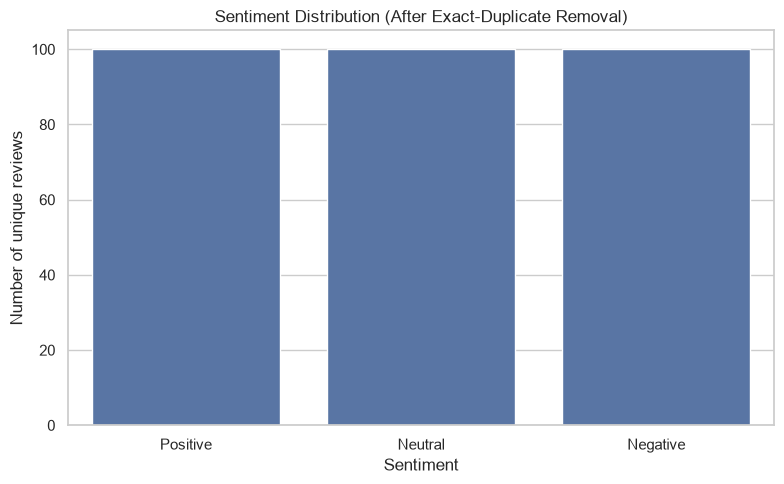

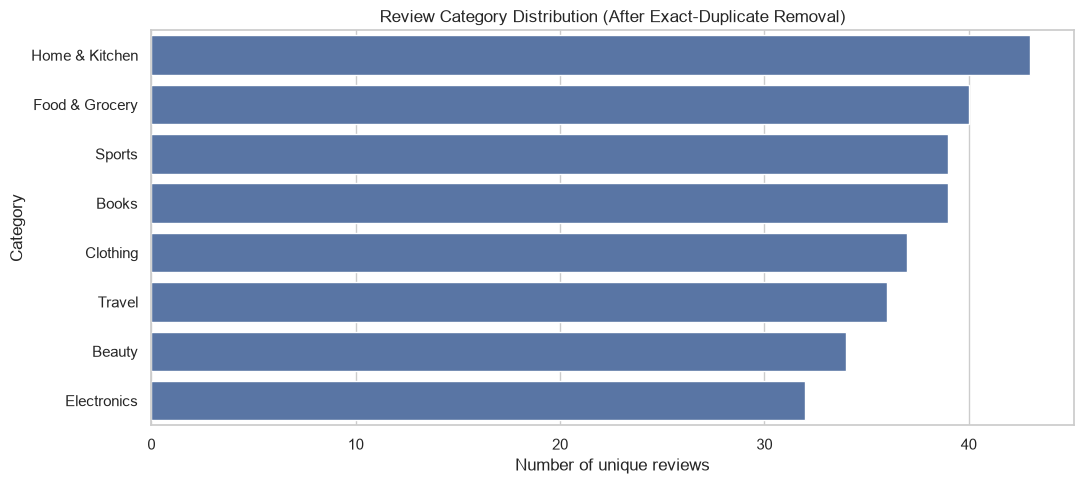

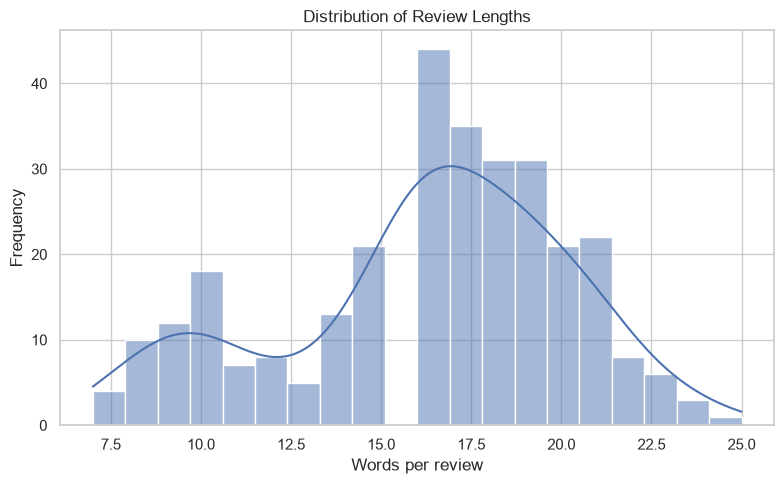

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(
    data=df,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)
plt.title("Sentiment Distribution (After Exact-Duplicate Removal)")
plt.xlabel("Sentiment")
plt.ylabel("Number of unique reviews")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
sns.countplot(
    data=df,
    y="category",
    order=df["category"].value_counts().index
)
plt.title("Review Category Distribution (After Exact-Duplicate Removal)")
plt.xlabel("Number of unique reviews")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

df["review_length_words"] = df["review_text"].str.split().str.len()
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="review_length_words", bins=20, kde=True)
plt.title("Distribution of Review Lengths")
plt.xlabel("Words per review")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## 5. Text preprocessing
The same function is used in the notebook and the Streamlit app. Punctuation and digits are replaced with spaces, and repeated whitespace is collapsed.

**Important:** We do not remove English stop words. Words such as `not` and `never` can reverse sentiment, so removing them may damage sentiment classification.

In [7]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review_text"].apply(clean_text)

display(df[["review_text", "clean_review"]].head(5))

# Remove any rows that became empty after preprocessing
df = df[df["clean_review"].ne("")].reset_index(drop=True)
print("Rows available for modeling:", len(df))

,review_text,clean_review
0,This product exceeded my expectations in sever...,this product exceeded my expectations in sever...
1,The item is uncomfortable to use and poorly de...,the item is uncomfortable to use and poorly de...
2,The product comes with a charging adapter and ...,the product comes with a charging adapter and ...
3,Customer support was slow and did not solve my...,customer support was slow and did not solve my...
4,"The design is simple, attractive, and comforta...",the design is simple attractive and comfortabl...


Rows available for modeling: 300


## 6. Train-test split
An 80:20 stratified split is used. Because exact duplicate review texts have already been removed, identical reviews cannot leak across the train and test sets.

In [8]:
X = df["clean_review"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining class counts:")
display(y_train.value_counts().to_frame("Count"))
print("\nTesting class counts:")
display(y_test.value_counts().to_frame("Count"))

Training rows: 240
Testing rows: 60

Training class counts:


,Count
sentiment,
Negative,80
Neutral,80
Positive,80



Testing class counts:


,Count
sentiment,
Negative,20
Positive,20
Neutral,20


## 7. Baseline model training and comparison
Three classifiers are compared using the same TF-IDF representation. Macro-averaged precision, recall and F1-score give equal weight to each sentiment class.

In [9]:
baseline_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        class_weight="balanced"
    )
}

baseline_rows = []
baseline_pipelines = {}

for model_name, classifier in baseline_models.items():
    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
        ("clf", classifier)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    baseline_pipelines[model_name] = pipeline

    baseline_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (macro)": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, predictions, average="macro", zero_division=0)
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    "F1-score (macro)", ascending=False
).reset_index(drop=True)

display(baseline_results.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,1.0000,1.0000,1.0000,1.0000
1,Multinomial Naive Bayes,1.0000,1.0000,1.0000,1.0000
2,Random Forest,0.9333,0.9444,0.9333,0.9341


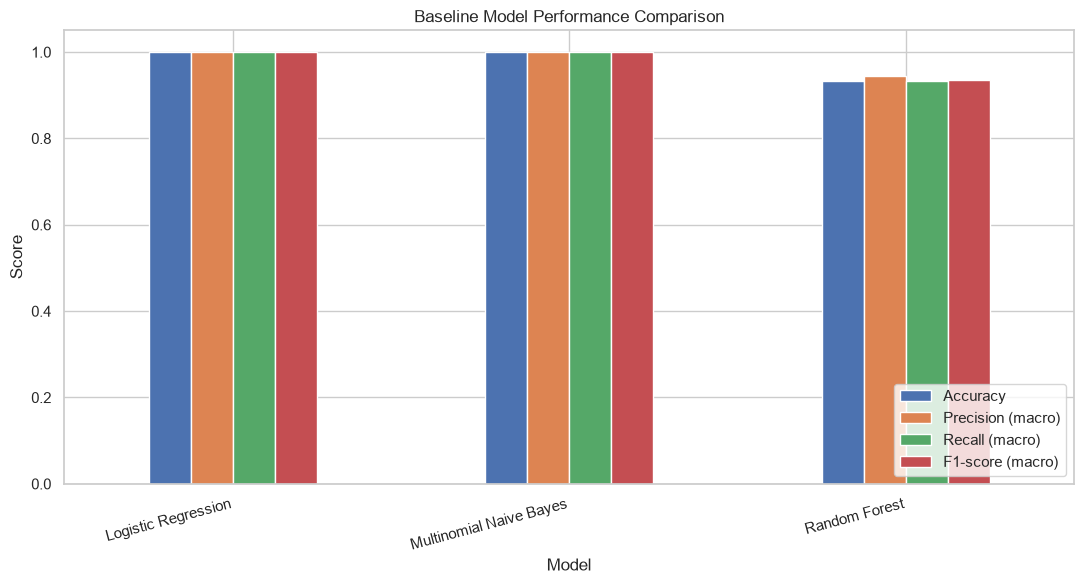

In [10]:
baseline_plot = baseline_results.set_index("Model")[
    ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
]
baseline_plot.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Baseline Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 8. Hyperparameter tuning and probability calibration
The final candidate is Logistic Regression with sigmoid probability calibration. GridSearchCV selects the TF-IDF vocabulary size and Logistic Regression regularization strength using macro F1-score.

Calibration is fitted inside the training folds. The held-out test set is not used for model selection.

In [11]:
base_classifier = LogisticRegression(
    max_iter=2000,
    random_state=RANDOM_STATE
)

calibrated_classifier = CalibratedClassifierCV(
    estimator=base_classifier,
    method="sigmoid",
    cv=3
)

full_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("clf", calibrated_classifier)
])

param_grid = {
    "tfidf__max_features": [3000, 5000],
    "clf__estimator__C": [0.1, 1.0, 10.0]
}

grid_search = GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_

print("Best parameters:", grid_search.best_params_)
print("Best mean CV macro F1-score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'clf__estimator__C': 1.0, 'tfidf__max_features': 3000}
Best mean CV macro F1-score: 1.0


## 9. Final test-set evaluation
The following metrics are calculated once on the held-out test set. Multiclass ROC-AUC uses one-vs-rest (OVR) with macro averaging.

In [12]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)
class_labels = best_model.classes_

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "ROC-AUC (macro OVR)": roc_auc_score(
        y_test, y_prob, multi_class="ovr", average="macro", labels=class_labels
    )
}

final_metrics_df = pd.DataFrame(
    {"Metric": list(final_metrics.keys()), "Score": list(final_metrics.values())}
)

display(final_metrics_df.round(4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=class_labels, zero_division=0))

,Metric,Score
0,Accuracy,1.0
1,Precision (macro),1.0
2,Recall (macro),1.0
3,F1-score (macro),1.0
4,ROC-AUC (macro OVR),1.0



Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        20
     Neutral       1.00      1.00      1.00        20
    Positive       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



## 10. Confusion matrix

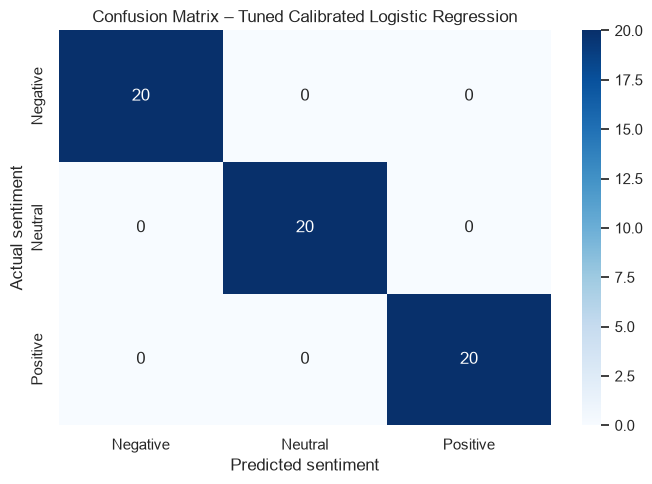

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=class_labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)
plt.title("Confusion Matrix – Tuned Calibrated Logistic Regression")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

## 11. Save the complete trained pipeline
The saved pipeline includes both TF-IDF vectorization and the calibrated classifier. The Streamlit app can therefore pass cleaned text directly to `predict()` and `predict_proba()` without rebuilding the vectorizer.

In [14]:
# Resolve project root whether notebook is launched from root or notebooks/
cwd = Path.cwd()
project_root = cwd.parent if cwd.name.lower() == "notebooks" else cwd

model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "sentiment_pipeline.pkl"
joblib.dump(best_model, model_path)

print("Model saved successfully:")
print(model_path)

Model saved successfully:
c:\Users\Debarun Kanjilal\Downloads\models\sentiment_pipeline.pkl


## 12. Final conclusion and limitation
This project demonstrates an end-to-end sentiment-analysis workflow using text preprocessing, TF-IDF bigrams, three baseline classifiers, cross-validation, hyperparameter tuning, probability calibration, evaluation metrics and model serialization.

**Dataset limitation:** Although the CSV contains 10,000 rows, it contains only 300 unique review texts. The duplicates were removed before splitting to avoid train-test leakage. The resulting test set is small (60 reviews), so the measured scores may not generalize to new real-world customer reviews. The very high scores, if observed, should not be interpreted as proof of production-level performance. A larger dataset containing more unique reviews is needed for a stronger evaluation.

The model's probability output is a calibrated estimate from this fitted model, not a guarantee that a prediction is correct.